# Project: Breast Cancer (SEER) & FUTURE-AI

This notebook prepares the data **identically for all groups**, so results stay comparable even if you choose different FUTURE-AI criteria. It contains:

1. Dataset import
2. Label creation (5-year Overall Survival)
3. Train/test split and Cross-Validation
4. Data pre-processing

**From here on, the project is yours.** You will need to add:
- **EDA** — explore the dataset: distributions, subgroups, any data quality issues, relationships between variables and with the outcome
- **Machine Learning pipeline** — feature engineering/selection, model choice and comparison, hyperparameter tuning (using the Cross-Validation already set up), final evaluation on the test set
- **FUTURE-AI assessment** — Fairness, Universality, Traceability, Usability, Robustness, Explainability and design a concrete analysis for each

**Important rule**: the test set created in this notebook must be used **only for the final evaluation** of the chosen model. To compare models/hyperparameters during development, use Cross-Validation on the train set — never the test set, otherwise the final results will be optimistically biased ("procedural" data leakage).



## 1. Dataset import

In [6]:
import pandas as pd
import numpy as np

SEED = 42
np.random.seed(SEED)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

### Load the dataset in VS Code or Google Colab

The notebook first looks for the CSV in the project folder or current working directory. If it is not found locally and the notebook is running in Colab, it mounts Google Drive and uses the configured Drive path.


In [7]:
from pathlib import Path

CSV_NAME = "Copia di SEER Breast Cancer Dataset .csv"
PROJECT_DIR = Path(r"C:\Progetti\neuroengineering_course\progetto")
LOCAL_PATHS = [PROJECT_DIR / CSV_NAME, Path.cwd() / CSV_NAME]

# Prefer the local CSV when it is available, including in VS Code.
dataset_path = next((path for path in LOCAL_PATHS if path.is_file()), None)

if dataset_path is None:
    try:
        from google.colab import drive
    except ImportError as exc:
        raise FileNotFoundError(
            "CSV not found locally. Place it in the project folder or update PROJECT_DIR."
        ) from exc

    # This branch runs in Colab when the CSV is not present locally.
    drive.mount("/content/drive")
    dataset_path = Path("/content/drive/MyDrive/progettoneuro") / CSV_NAME

if not dataset_path.is_file():
    raise FileNotFoundError(f"CSV not found at {dataset_path}. Check its location.")

print(f"Dataset path: {dataset_path}")


Dataset path: C:\Progetti\neuroengineering_course\progetto\Copia di SEER Breast Cancer Dataset .csv


In [8]:
# Read the dataset selected in the previous cell.
df = pd.read_csv(dataset_path)

print("Raw shape:", df.shape)
df.head()


Raw shape: (4024, 16)


,Age,Race,Marital Status,Unnamed: 3,T Stage,N Stage,6th Stage,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,43,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),NaN,T2,N3,IIIC,Moderately differentiated; Grade II,Regional,40,Positive,Positive,19,11,1,Alive
1,47,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),NaN,T2,N2,IIIA,Moderately differentiated; Grade II,Regional,45,Positive,Positive,25,9,2,Alive
2,67,White,Married (including common law),NaN,T2,N1,IIB,Poorly differentiated; Grade III,Regional,25,Positive,Positive,4,1,2,Dead
3,46,White,Divorced,NaN,T1,N1,IIA,Moderately differentiated; Grade II,Regional,19,Positive,Positive,26,1,2,Dead
4,63,White,Married (including common law),NaN,T2,N2,IIIA,Moderately differentiated; Grade II,Regional,35,Positive,Positive,21,5,3,Dead


The file contains two small technical artifacts that must be removed before any analysis (these are not part of the EDA you will do — they are defects of the CSV file, not of the clinical content):
- an unnamed, completely empty column;
- 1 duplicate row.

In [9]:
df = df.drop(columns=["Unnamed: 3"]).copy() #to remove empty colums
df.columns = [c.strip() for c in df.columns]  # removes accidental whitespace in column names
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after minimal cleaning:", df.shape)
assert df.isna().sum().sum() == 0, "there should be no missing values left" #there are no any missing value
df.head()

Shape after minimal cleaning: (4023, 15)


,Age,Race,Marital Status,T Stage,N Stage,6th Stage,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,43,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),T2,N3,IIIC,Moderately differentiated; Grade II,Regional,40,Positive,Positive,19,11,1,Alive
1,47,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),T2,N2,IIIA,Moderately differentiated; Grade II,Regional,45,Positive,Positive,25,9,2,Alive
2,67,White,Married (including common law),T2,N1,IIB,Poorly differentiated; Grade III,Regional,25,Positive,Positive,4,1,2,Dead
3,46,White,Divorced,T1,N1,IIA,Moderately differentiated; Grade II,Regional,19,Positive,Positive,26,1,2,Dead
4,63,White,Married (including common law),T2,N2,IIIA,Moderately differentiated; Grade II,Regional,35,Positive,Positive,21,5,3,Dead


### Data dictionary

| Column | Meaning |
|---|---|
| `Age` | Age at diagnosis (years) |
| `Race` | Ethnicity (SEER categories: White / Black / Other) |
| `Marital Status` | Marital status at diagnosis |
| `T Stage` | Extent of the primary tumor (AJCC), T1 (small) → T4 (extensive) |
| `N Stage` | Regional lymph node involvement, N1 → N3 (increasing) |
| `6th Stage` | Overall AJCC 6th edition stage (combines T, N, and metastatic status) |
| `Grade` | Histologic differentiation grade of the tumor (I = well differentiated → IV = anaplastic) |
| `A Stage` | Regional (localized/loco-regional) vs Distant (metastatic) |
| `Tumor Size` | Tumor diameter (mm) |
| `Estrogen Status` / `Progesterone Status` | Hormone receptor status (Positive/Negative) |
| `Regional Node Examined` | No. of lymph nodes surgically examined |
| `Reginol Node Positive` | No. of lymph nodes found positive (with metastasis) |
| `Survival Months` | Months of observed follow-up |
| `Status` | Status at the end of follow-up: Alive (alive/censored) or Dead (deceased) |

`Survival Months` and `Status` are **only** used to build the label — they are not legitimate model features (using them would be data leakage: they would use the very outcome you're trying to predict).

## 2. Label creation — 5-year Overall Survival

The task is: **predict whether a patient will have died within 5 years (60 months) of diagnosis**, using only clinico-pathological information available at diagnosis/initial staging.

Not all patients can be used: anyone still "Alive" with a shorter follow-up than 60 months is still under observation — their 5-year outcome is not known (censoring), and they must be excluded rather than forced into one of the two classes.

- **label = 1** (death within 5 years): `Status == "Dead"` and `Survival Months < 60`
- **label = 0** (survives to 5 years): `Survival Months >= 60` (regardless of what happens afterwards)
- **excluded**: `Status == "Alive"` and `Survival Months < 60` (unknown outcome)


In [10]:
HORIZON = 60  # months

survived = df[df["Survival Months"] >= HORIZON].copy()
survived["label"] = 0

died_early = df[(df["Status"] == "Dead") & (df["Survival Months"] < HORIZON)].copy()
died_early["label"] = 1

excluded = df[(df["Status"] == "Alive") & (df["Survival Months"] < HORIZON)]

task_df = pd.concat([survived, died_early], ignore_index=True)

print(f"Evaluable patients: {len(task_df)}  |  excluded (censored before 5 years): {len(excluded)} "
      f"({len(excluded)/len(df)*100:.1f}% of the original cohort)")
print(task_df["label"].value_counts(normalize=True).rename("share").round(3))

Evaluable patients: 3270  |  excluded (censored before 5 years): 753 (18.7% of the original cohort)
label
0    0.863
1    0.137
Name: share, dtype: float64


## 3. Train/test split and Cross-Validation

Stratified split (keeps the same proportion of events in train and test) with a fixed seed, so all groups start from the same data.

The columns `Survival Months`, `Status` (used to build the label) and the `label` itself are separated out from `X`. **`6th Stage` is not removed here**: it's one of the questions you should ask yourselves during EDA and feature engineering (hint: check its relationship with `T Stage`/`N Stage`/`A Stage`).


In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold

LEAKAGE_COLS = ["Survival Months", "Status", "label"]  # Never use outcome information as a feature.
X = task_df.drop(columns=LEAKAGE_COLS).copy()
y = task_df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Event prevalence (label=1) — train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))


Train: (2452, 13)  Test: (818, 13)
Event prevalence (label=1) — train: 0.137  test: 0.137


In [ ]:
# Cross-Validation to use for comparing models/hyperparameters ON THE TRAIN SET
# (never on the test set: that is reserved for final evaluation)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

## 4. Feature Groups for the EDA

List the original numerical and categorical features so the exploratory analysis can use the appropriate summaries. The ordered variables are included among the categorical features at this stage. No scaling or encoding is fitted here.


In [ ]:
NUM_COLS = ["Age", "Tumor Size", "Regional Node Examined", "Reginol Node Positive"]
ORD_COLS = ["T Stage", "N Stage", "Grade"]  # These categories have a meaningful clinical order.
CAT_COLS = ["Race", "Marital Status", "6th Stage", "A Stage",
            "Estrogen Status", "Progesterone Status"]
assert set(NUM_COLS) | set(ORD_COLS) | set(CAT_COLS) == set(X_train.columns)


## Project Checklist

The following sections explore the original training features, examine their relationships, and then create the Positive Node Ratio and define the model preprocessor. Model development, evaluation and FUTURE-AI assessment remain to be completed.


## 5. Exploratory Data Analysis (EDA)

This section describes the training set before model development. Class **0** means observed survival of at least 60 months; class **1** means death from any cause before 60 months. Patients recorded alive with shorter follow-up were excluded because their five-year outcome is unknown. This exclusion may affect how representative the analyzed cohort is.

All comparisons below use `X_train` and `y_train`; the held-out test set remains reserved for final model evaluation. Group differences are descriptive associations, not evidence of causation.


In [ ]:
import matplotlib.pyplot as plt
from IPython.display import display
import textwrap

# Keep the outcome aligned with its original training-set rows.
assert X_train.index.equals(y_train.index)
eda_train = X_train.copy()
eda_train["label"] = y_train

# Reuse the feature groups defined in the preprocessing section.
EDA_NUM_COLS = NUM_COLS
EDA_CAT_COLS = ORD_COLS + CAT_COLS
assert set(EDA_NUM_COLS + EDA_CAT_COLS) == set(X_train.columns)

print(f"Cleaned cohort: {len(df):,} patients")
print(f"Excluded because of censoring before 5 years: {len(excluded):,}")
print(f"Evaluable cohort: {len(task_df):,} patients")
print(f"Training set analyzed below: {len(eda_train):,} patients")


Cleaned cohort: 4,023 patients
Excluded because of censoring before 5 years: 753
Evaluable cohort: 3,270 patients
Training set analyzed below: 2,452 patients


### 5.1 Outcome Distribution

The classes are imbalanced. The table and chart show how many training patients are in each outcome group. The positive class is death before five years. This information helps us interpret later comparisons and select evaluation metrics.


,Patients,Training set (%)
0: Survived at least 5 years,2115,86.3
1: Died before 5 years,337,13.7


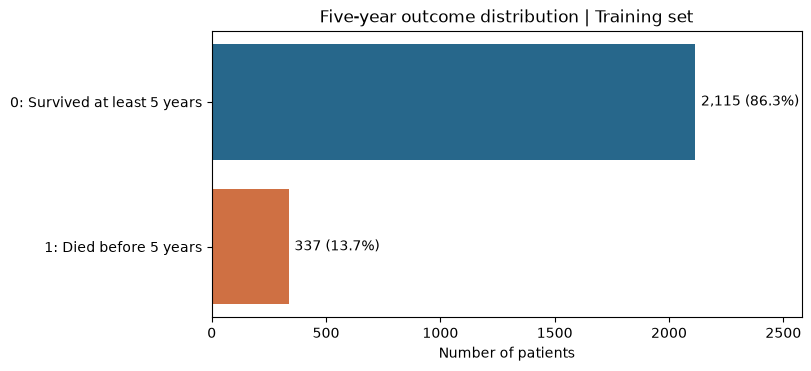

In [ ]:
outcome_counts = eda_train["label"].value_counts().reindex([0, 1], fill_value=0)
outcome_table = pd.DataFrame({
    "Patients": outcome_counts,
    "Training set (%)": (100 * outcome_counts / len(eda_train)).round(1),
})
outcome_table.index = ["0: Survived at least 5 years", "1: Died before 5 years"]
display(outcome_table)

fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
bars = ax.barh(outcome_table.index, outcome_counts.to_numpy(), color=["#27678b", "#cf7043"])
ax.invert_yaxis()
ax.set_title("Five-year outcome distribution | Training set")
ax.set_xlabel("Number of patients")
ax.set_xlim(0, max(outcome_counts) * 1.22)
for bar, count in zip(bars, outcome_counts):
    ax.text(count + len(eda_train) * 0.01, bar.get_y() + bar.get_height() / 2,
            f"{count:,} ({count / len(eda_train):.1%})", va="center")
plt.show()


## 6. Numerical Variables

The four original numerical features describe age, tumor size and regional lymph node counts. Summary statistics show center, spread and observed range. Extreme observations may be clinically plausible; they should not be removed automatically.

### 6.1 Numerical Summary and Outcome Comparison

The first table summarizes the whole training set. The second compares the median of each feature between the two outcome groups; medians alone do not show the full distribution or establish a causal relationship.


In [ ]:
numeric_summary = eda_train[EDA_NUM_COLS].describe().T.rename(columns={
    "count": "Patients", "mean": "Mean", "std": "Std. deviation",
    "min": "Minimum", "25%": "25th percentile", "50%": "Median",
    "75%": "75th percentile", "max": "Maximum",
})
display(numeric_summary.round(2))

median_by_outcome = eda_train.groupby("label")[EDA_NUM_COLS].median().T
median_by_outcome.columns = ["Class 0: survived ≥5 years", "Class 1: died <5 years"]
print("Median by outcome group")
display(median_by_outcome.round(2))


,Patients,Mean,Std. deviation,Minimum,25th percentile,Median,75th percentile,Maximum
Age,2452.0,54.15,8.99,30.0,47.0,55.0,62.0,69.0
Tumor Size,2452.0,30.76,21.31,1.0,16.0,25.0,38.0,140.0
Regional Node Examined,2452.0,14.42,8.09,1.0,9.0,14.0,19.0,60.0
Reginol Node Positive,2452.0,4.27,5.21,1.0,1.0,2.0,5.0,46.0


Median by outcome group


,Class 0: survived ≥5 years,Class 1: died <5 years
Age,54.0,57.0
Tumor Size,23.0,33.0
Regional Node Examined,14.0,14.0
Reginol Node Positive,2.0,5.0


### 6.2 Histograms: Distribution of Each Numerical Feature

Each histogram shows the number of training patients in each range. The panels use the original units, making it easier to see skewness, common values and long tails.


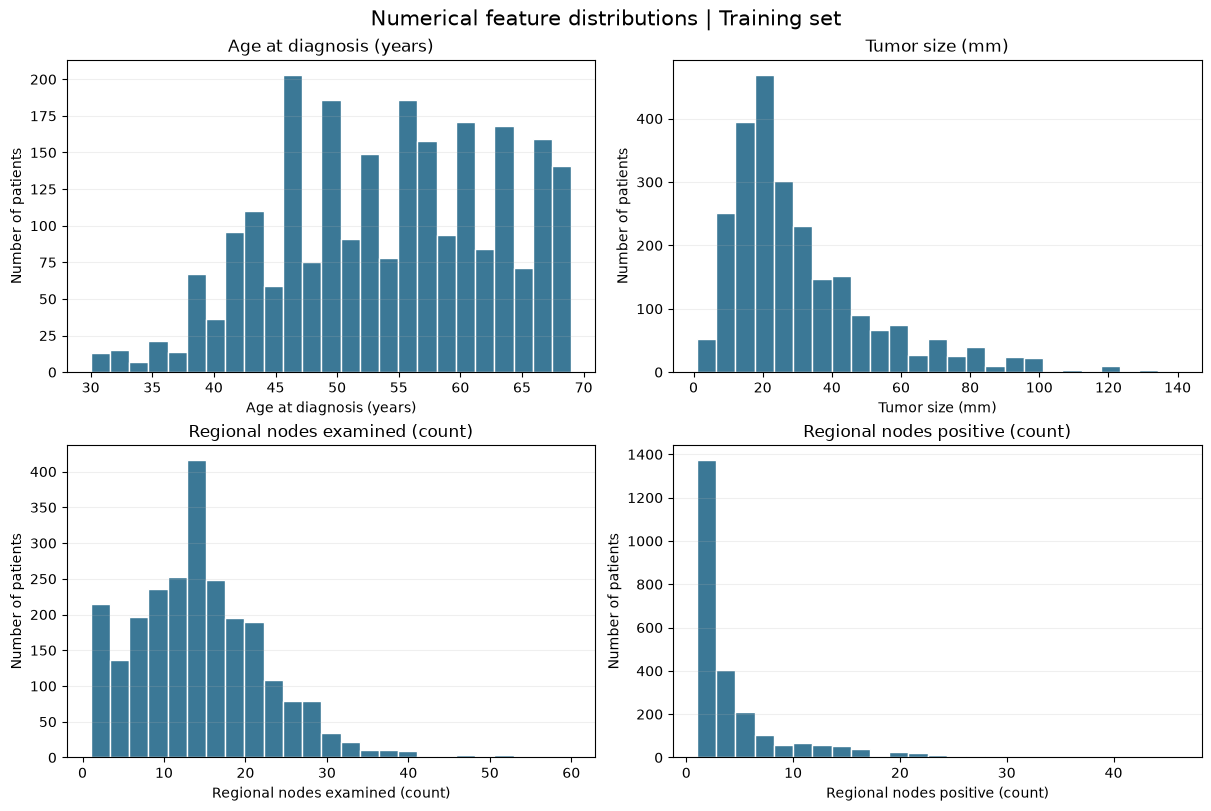

In [ ]:
NUM_LABELS = {
    "Age": "Age at diagnosis (years)",
    "Tumor Size": "Tumor size (mm)",
    "Regional Node Examined": "Regional nodes examined (count)",
    "Reginol Node Positive": "Regional nodes positive (count)",
}
n_rows = (len(EDA_NUM_COLS) + 1) // 2
fig, axes = plt.subplots(n_rows, 2, figsize=(12, 4 * n_rows), layout="constrained")
for ax, col in zip(axes.flat, EDA_NUM_COLS):
    ax.hist(eda_train[col].dropna(), bins=25, color="#3b7896", edgecolor="white")
    ax.set_title(NUM_LABELS[col])
    ax.set_xlabel(NUM_LABELS[col])
    ax.set_ylabel("Number of patients")
    ax.grid(axis="y", alpha=0.2)
for ax in list(axes.flat)[len(EDA_NUM_COLS):]:
    ax.remove()  # Hide an unused panel when the number of features is odd.
fig.suptitle("Numerical feature distributions | Training set", fontsize=15)
plt.show()


### 6.3 Box Plots: Numerical Features by Outcome

The center line is the median and the box spans the middle 50% of each group. Whiskers and individual points show the spread using the standard box-plot rule; points beyond the whiskers are not necessarily data errors. Compare both the overlap and the sample sizes, as the outcome groups are unequal.


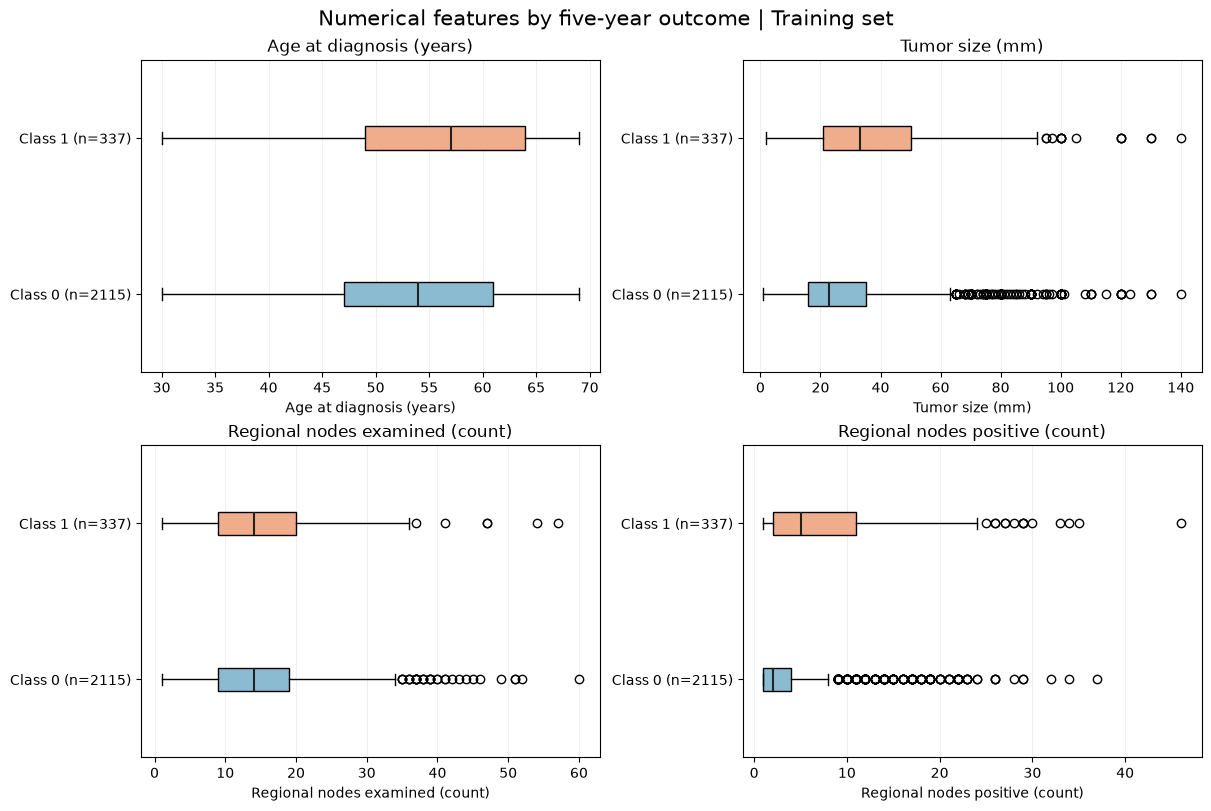

In [ ]:
from inspect import signature

n_rows = (len(EDA_NUM_COLS) + 1) // 2
fig, axes = plt.subplots(n_rows, 2, figsize=(12, 4 * n_rows), layout="constrained")
for ax, col in zip(axes.flat, EDA_NUM_COLS):
    groups = [eda_train.loc[eda_train["label"] == label, col].dropna() for label in (0, 1)]
    # Matplotlib renamed the horizontal-orientation option in version 3.10.
    orientation = {"orientation": "horizontal"} if "orientation" in signature(ax.boxplot).parameters else {"vert": False}
    boxes = ax.boxplot(groups, patch_artist=True, **orientation,
                       medianprops={"color": "#222222", "linewidth": 1.5})
    for patch, color in zip(boxes["boxes"], ["#8bbbd0", "#efad8b"]):
        patch.set_facecolor(color)
    ax.set_yticks([1, 2], [f"Class 0 (n={len(groups[0])})", f"Class 1 (n={len(groups[1])})"])
    ax.set_title(NUM_LABELS[col])
    ax.set_xlabel(NUM_LABELS[col])
    ax.grid(axis="x", alpha=0.2)
for ax in list(axes.flat)[len(EDA_NUM_COLS):]:
    ax.remove()  # Hide an unused panel when the number of features is odd.
fig.suptitle("Numerical features by five-year outcome | Training set", fontsize=15)
plt.show()


### 6.4 Basic Data-Quality Checks

Check missing values and whether the number of positive nodes exceeds the number examined. A passing check does not prove every observation is correct; it only addresses these specific conditions.


In [ ]:
missing_by_feature = eda_train[X_train.columns].isna().sum().rename("Missing values")
display(missing_by_feature.to_frame())
node_inconsistencies = (eda_train["Reginol Node Positive"] > eda_train["Regional Node Examined"]).sum()
print(f"Patients with more positive nodes than examined: {node_inconsistencies}")


,Missing values
Age,0
Race,0
Marital Status,0
T Stage,0
N Stage,0
6th Stage,0
Grade,0
A Stage,0
Tumor Size,0
Estrogen Status,0


Patients with more positive nodes than examined: 0


## 7. Categorical Variables

For each variable, the table and chart show the number of training patients and the percentage who died before five years **within that category**. The dashed line marks the overall event percentage in the training set. Percentages from small groups, such as Grade IV, should be interpreted cautiously.

These comparisons are descriptive. They do not adjust for other clinical or social variables and do not identify the cause of group differences.


In [ ]:
# Keep clinically ordered categories in their meaningful order in tables and plots.
CATEGORY_ORDER = {
    "T Stage": ["T1", "T2", "T3", "T4"],
    "N Stage": ["N1", "N2", "N3"],
    "6th Stage": ["IIA", "IIB", "IIIA", "IIIB", "IIIC"],
    "Grade": ["Well differentiated; Grade I", "Moderately differentiated; Grade II",
              "Poorly differentiated; Grade III", "Undifferentiated; anaplastic; Grade IV"],
}

def show_categorical_eda(column):
    # Calculate counts and the event proportion within each category.
    table = eda_train.groupby(column, dropna=False)["label"].agg(
        Patients="size", Events="sum", event_rate="mean"
    )
    if column in CATEGORY_ORDER:
        ordered = [value for value in CATEGORY_ORDER[column] if value in table.index]
        ordered += [value for value in table.index if value not in ordered]
        table = table.loc[ordered]
    else:
        table = table.sort_values("Patients", ascending=False)
    table["Training set (%)"] = 100 * table["Patients"] / len(eda_train)
    table["Deaths before 5 years (%)"] = 100 * table["event_rate"]
    shown = table[["Patients", "Training set (%)", "Events", "Deaths before 5 years (%)"]]
    display(shown.round(1))

    labels = ["\n".join(textwrap.wrap(str(value), width=30)) for value in table.index]
    positions = np.arange(len(table))
    fig, (ax_count, ax_rate) = plt.subplots(
        1, 2, figsize=(12, max(3.5, len(table) * 0.65 + 2)),
        gridspec_kw={"width_ratios": [1.1, 1]}, layout="constrained"
    )
    ax_count.barh(positions, table["Patients"], color="#3b7896")
    ax_count.set_yticks(positions, labels)
    ax_count.invert_yaxis()
    ax_count.set_xlabel("Number of patients")
    ax_count.set_title("Category size")
    ax_count.set_xlim(0, table["Patients"].max() * 1.22)
    for y, count in zip(positions, table["Patients"]):
        ax_count.text(count + table["Patients"].max() * 0.02, y, f"{count:,}", va="center")

    rates = table["Deaths before 5 years (%)"]
    ax_rate.barh(positions, rates, color="#d27d55")
    ax_rate.set_yticks(positions, [""] * len(positions))
    ax_rate.invert_yaxis()
    overall_rate = 100 * eda_train["label"].mean()
    ax_rate.axvline(overall_rate, color="#333333", linestyle="--", linewidth=1,
                    label=f"Overall: {overall_rate:.1f}%")
    ax_rate.set_xlabel("Deaths before 5 years (%)")
    ax_rate.set_title("Outcome within each category")
    ax_rate.set_xlim(0, max(rates.max(), overall_rate) * 1.30 + 1)
    for y, rate in zip(positions, rates):
        ax_rate.text(rate + 0.7, y, f"{rate:.1f}%", va="center")
    ax_rate.legend(loc="lower right", fontsize=9)
    fig.suptitle(f"{column} | Training set", fontsize=14)
    plt.show()


### 7.1 Race

Compare representation and outcome proportions across the dataset categories. Unequal group sizes and the broad Other category matter for later fairness analysis.


,Patients,Training set (%),Events,Deaths before 5 years (%)
Race,,,,
White,2083,85.0,280,13.4
Black,186,7.6,42,22.6
"Other (American Indian/AK Native, Asian/Pacific Islander)",183,7.5,15,8.2


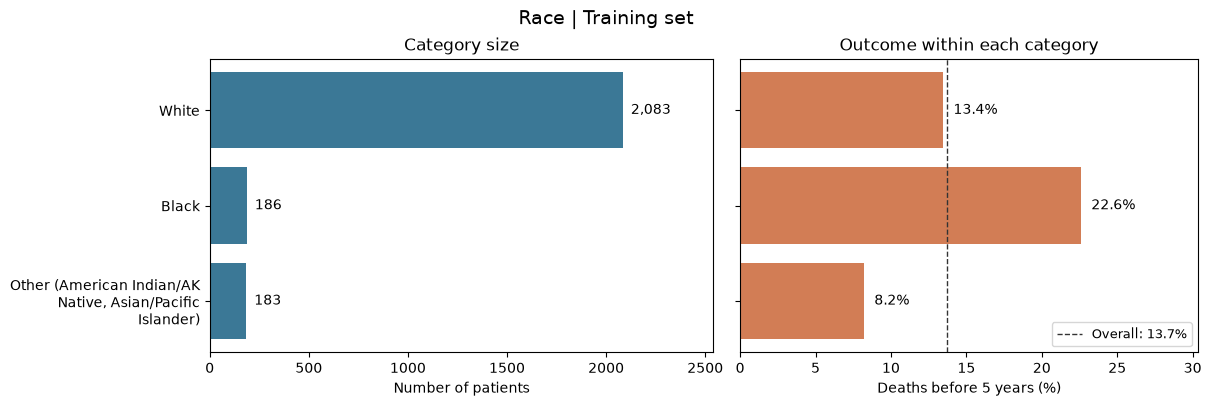

In [ ]:
show_categorical_eda("Race")


### 7.2 Marital Status

Examine the distribution and note groups with few patients. Any association can reflect multiple social and clinical factors.


,Patients,Training set (%),Events,Deaths before 5 years (%)
Marital Status,,,,
Married (including common law),1582,64.5,182,11.5
Single (never married),374,15.3,61,16.3
Divorced,318,13.0,57,17.9
Widowed,148,6.0,28,18.9
Separated,30,1.2,9,30.0


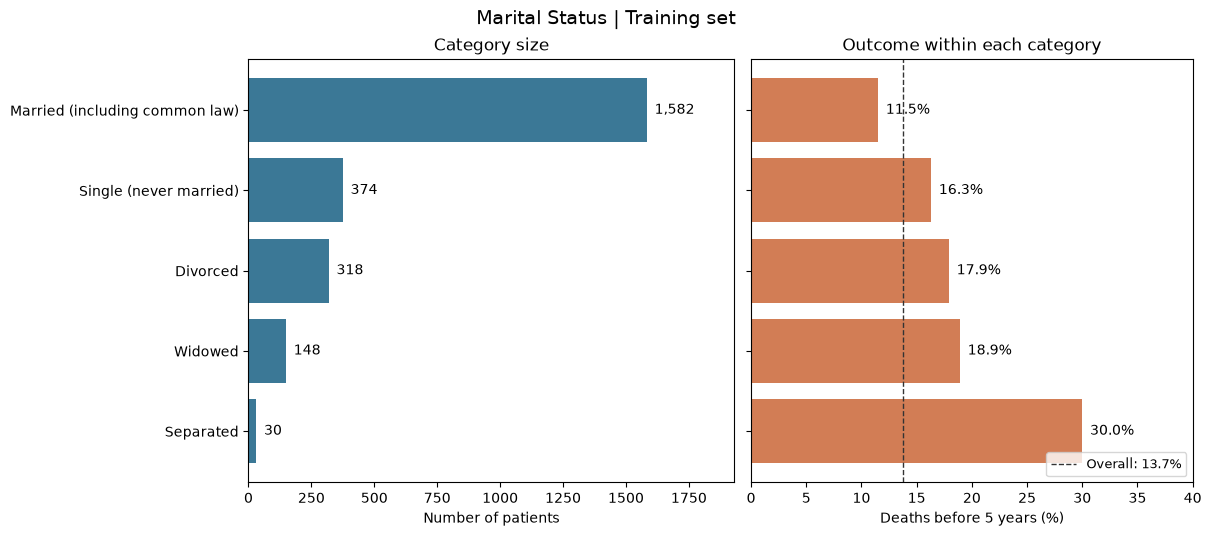

In [ ]:
show_categorical_eda("Marital Status")


### 7.3 T Stage

Compare the ordered primary tumor stages. The percentages describe this training sample, rather than the effect of stage alone.


,Patients,Training set (%),Events,Deaths before 5 years (%)
T Stage,,,,
T1,971,39.6,78,8.0
T2,1068,43.6,164,15.4
T3,340,13.9,69,20.3
T4,73,3.0,26,35.6


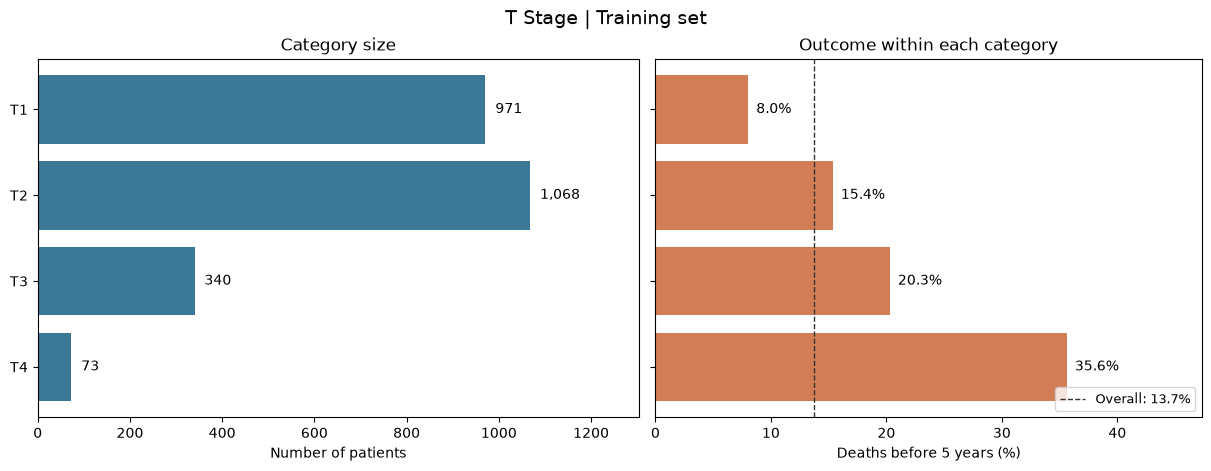

In [ ]:
show_categorical_eda("T Stage")


### 7.4 N Stage

Compare the ordered regional lymph node stages and the size of each group.


,Patients,Training set (%),Events,Deaths before 5 years (%)
N Stage,,,,
N1,1639,66.8,139,8.5
N2,500,20.4,90,18.0
N3,313,12.8,108,34.5


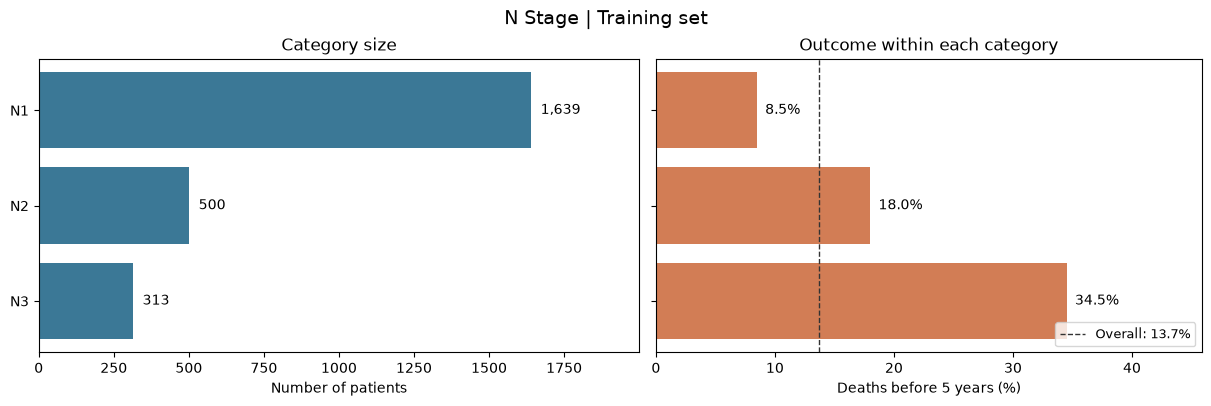

In [ ]:
show_categorical_eda("N Stage")


### 7.5 6th Stage

Inspect the overall stage and consider its overlap with T and N stages. Some categories may have few patients.


,Patients,Training set (%),Events,Deaths before 5 years (%)
6th Stage,,,,
IIA,793,32.3,51,6.4
IIB,661,27.0,63,9.5
IIIA,639,26.1,102,16.0
IIIB,46,1.9,13,28.3
IIIC,313,12.8,108,34.5


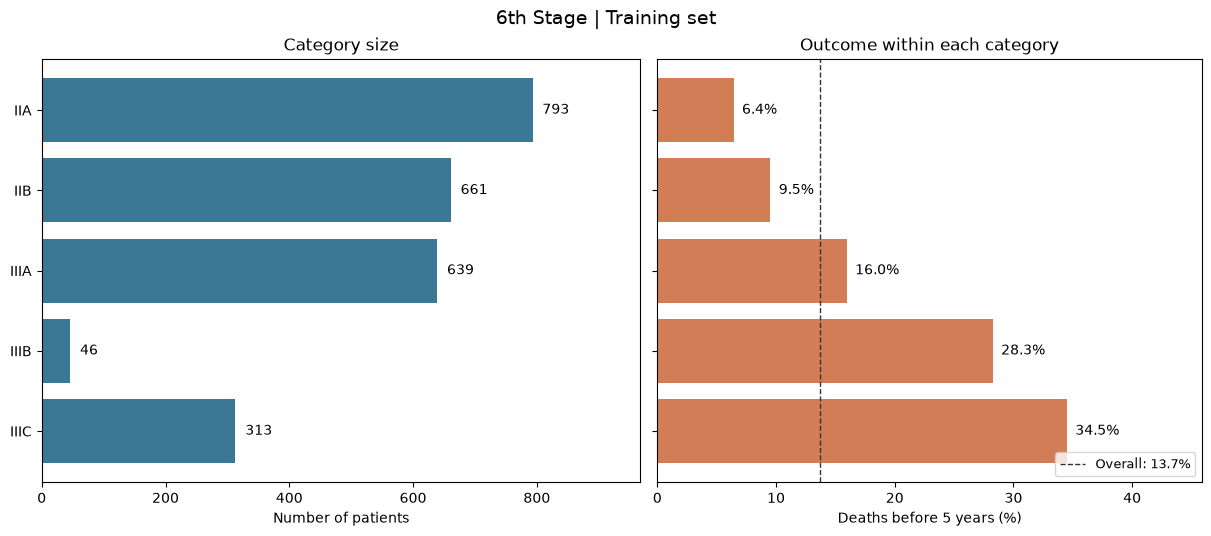

In [ ]:
show_categorical_eda("6th Stage")


### 7.6 Grade

Compare ordered histological grades. Pay particular attention to the small Grade IV group.


,Patients,Training set (%),Events,Deaths before 5 years (%)
Grade,,,,
Well differentiated; Grade I,303,12.4,19,6.3
Moderately differentiated; Grade II,1438,58.6,165,11.5
Poorly differentiated; Grade III,699,28.5,147,21.0
Undifferentiated; anaplastic; Grade IV,12,0.5,6,50.0


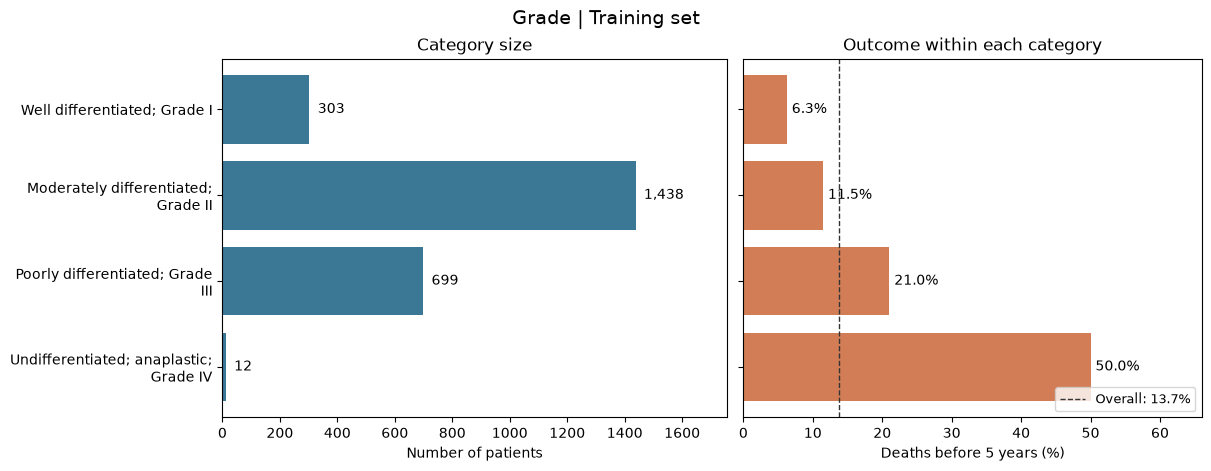

In [ ]:
show_categorical_eda("Grade")


### 7.7 A Stage

Compare Regional and Distant categories, and check group sizes before interpreting their percentages.


,Patients,Training set (%),Events,Deaths before 5 years (%)
A Stage,,,,
Regional,2397,97.8,317,13.2
Distant,55,2.2,20,36.4


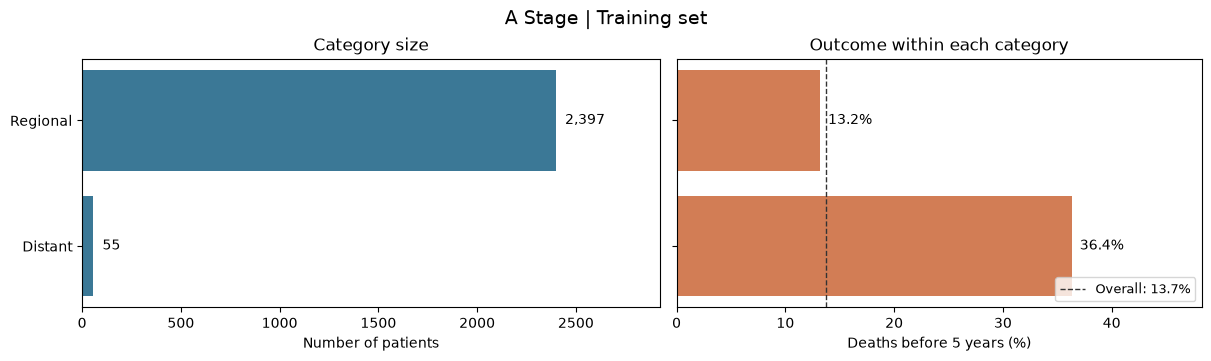

In [ ]:
show_categorical_eda("A Stage")


### 7.8 Estrogen Status

Compare receptor categories. The observed difference is not an adjusted effect of receptor status.


,Patients,Training set (%),Events,Deaths before 5 years (%)
Estrogen Status,,,,
Positive,2267,92.5,268,11.8
Negative,185,7.5,69,37.3


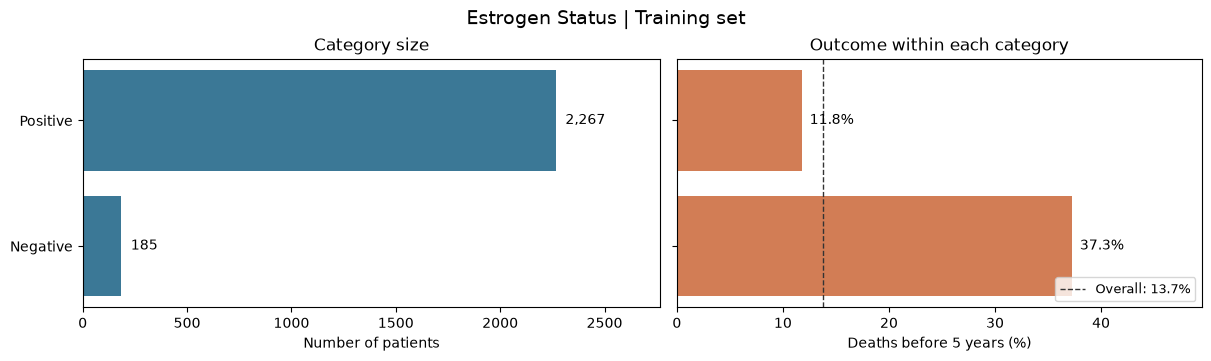

In [ ]:
show_categorical_eda("Estrogen Status")


### 7.9 Progesterone Status

Compare receptor categories and their within-group outcome proportions.


,Patients,Training set (%),Events,Deaths before 5 years (%)
Progesterone Status,,,,
Positive,2007,81.9,209,10.4
Negative,445,18.1,128,28.8


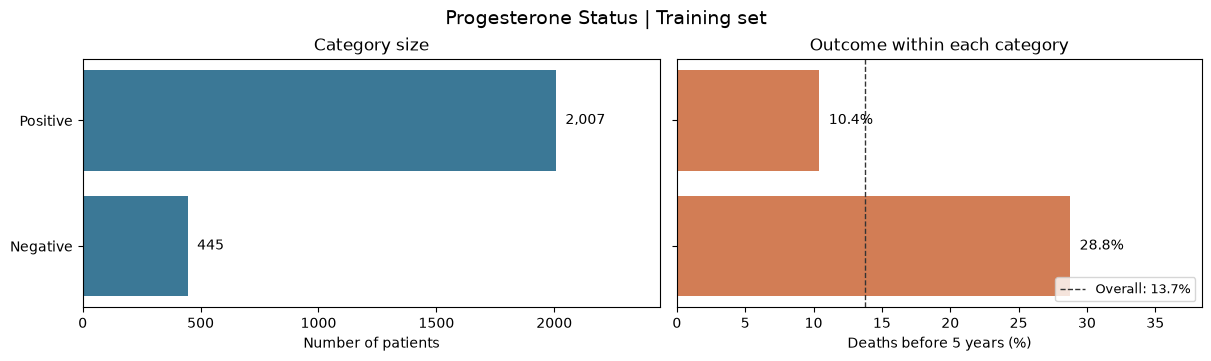

In [ ]:
show_categorical_eda("Progesterone Status")


## 8. EDA Interpretation and Next Decisions

- The class distribution should guide metric selection; accuracy alone can hide poor performance on class 1.
- Review numerical distributions before choosing transformations. Do not remove extreme values without checking their meaning.
- Small categorical groups can have unstable outcome proportions and deserve attention in model evaluation and fairness analysis.
- T Stage, N Stage and Grade have a clinical order; consider how to encode them and the assumptions this imposes for each model.
- 6th Stage is related to other staging variables. Assess feature redundancy during model development.
- Early-censored patients were excluded, and the data may not represent all patient populations. Consider these limits when interpreting results.


## 9. Relationships Between Features

This section compares **every pair of the 13 original input features** in the training set. We use raw training features, not the target or test set. Different methods are needed because numerical and categorical variables represent information differently:

- **Numerical–numerical:** Spearman rank correlation (−1 to +1), including direction.
- **Categorical–categorical:** Cramér’s V (0 to 1), a symmetric measure of association without direction.
- **Numerical–categorical:** correlation ratio η (0 to 1), describing how much of a numerical variable’s variation lies between categories, without direction.

The methods measure different relationships, so their values should not be compared as if they were the same metric. These are descriptive associations, not causation or an automatic rule for dropping features. Rare categories can make estimates unstable; uncorrected Cramér’s V can be inflated in sparse tables. T Stage, N Stage and Grade are treated as categories here, so Cramér’s V does not use their ordering.


In [ ]:
from itertools import combinations
from scipy.stats import chi2_contingency

# Use the original training features rather than encoded values or test data.
relationship_data = X_train.copy()
NUM_FEATURES = list(NUM_COLS)
CAT_FEATURES = list(ORD_COLS) + list(CAT_COLS)
assert set(NUM_FEATURES + CAT_FEATURES) == set(relationship_data.columns)

def cramers_v(first, second):
    # Calculate uncorrected Cramér's V using observations available for both features.
    pairs = pd.concat([first, second], axis=1).dropna()
    table = pd.crosstab(pairs.iloc[:, 0], pairs.iloc[:, 1])
    if table.shape[0] < 2 or table.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return float(np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1))))

def correlation_ratio(numerical, categorical):
    # Compare variation between category means with total numerical variation.
    pairs = pd.DataFrame({"value": numerical, "group": categorical}).dropna()
    if len(pairs) < 2 or pairs["group"].nunique() < 2:
        return np.nan
    total = ((pairs["value"] - pairs["value"].mean()) ** 2).sum()
    if total == 0:
        return np.nan
    groups = pairs.groupby("group")["value"].agg(["size", "mean"])
    between = (groups["size"] * (groups["mean"] - pairs["value"].mean()) ** 2).sum()
    return float(np.sqrt(np.clip(between / total, 0, 1)))

def plot_relationship_matrix(matrix, title, label, *, cmap, vmin, vmax):
    fig, ax = plt.subplots(figsize=(max(8, matrix.shape[1] * 1.3),
                                   max(4.5, matrix.shape[0] * 0.8)), layout="constrained")
    image = ax.imshow(matrix.to_numpy(dtype=float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(matrix.shape[1]), matrix.columns, rotation=40, ha="right", rotation_mode="anchor")
    ax.set_yticks(range(matrix.shape[0]), matrix.index)
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            value = matrix.iat[row, col]
            if pd.notna(value):
                red, green, blue, _ = image.cmap(image.norm(value))
                luminance = 0.2126 * red + 0.7152 * green + 0.0722 * blue
                color = "white" if luminance < 0.50 else "black"
                ax.text(col, row, f"{value:.2f}", ha="center", va="center", color=color, fontsize=9)
    ax.set_title(title)
    fig.colorbar(image, ax=ax, label=label, shrink=0.85)
    plt.show()


### 9.1 Numerical–Numerical Pairs: Spearman Correlation

Spearman correlation compares ranks. Positive values indicate that higher values tend to occur together; negative values indicate opposite rank trends. Values near zero do not rule out non-monotonic relationships. The diagonal compares each feature with itself.


,Age,Tumor Size,Regional Node Examined,Reginol Node Positive
Age,1.000,-0.111,-0.032,-0.001
Tumor Size,-0.111,1.000,0.133,0.339
Regional Node Examined,-0.032,0.133,1.000,0.378
Reginol Node Positive,-0.001,0.339,0.378,1.000


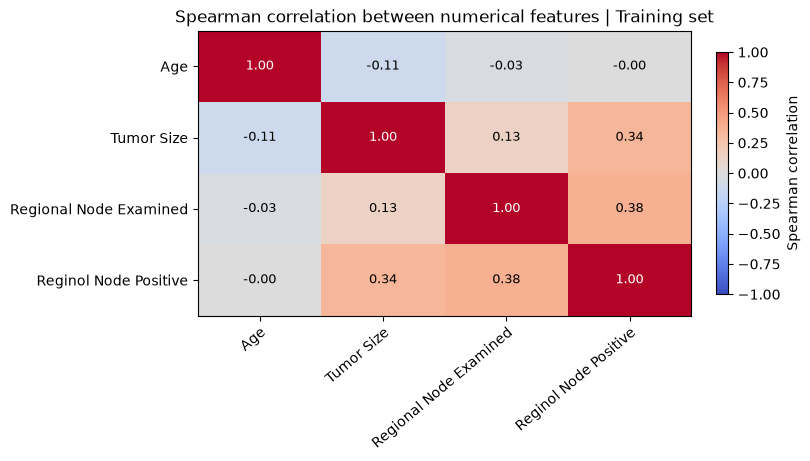

In [ ]:
spearman_matrix = relationship_data[NUM_FEATURES].corr(method="spearman")
display(spearman_matrix.round(3))
plot_relationship_matrix(spearman_matrix, "Spearman correlation between numerical features | Training set",
                         "Spearman correlation", cmap="coolwarm", vmin=-1, vmax=1)


### 9.2 Categorical–Categorical Pairs: Cramér’s V

Each off-diagonal cell summarizes one pair of categorical variables. Zero indicates little detected association and larger values indicate stronger association; the value has no positive or negative direction. Examine category counts before interpreting high scores, especially for rare Grade IV or small social groups. The diagonal is one for nonconstant features.


,T Stage,N Stage,Grade,Race,Marital Status,6th Stage,A Stage,Estrogen Status,Progesterone Status
T Stage,1.000,0.213,0.076,0.030,0.042,0.747,0.446,0.087,0.053
N Stage,0.213,1.000,0.127,0.032,0.058,0.909,0.253,0.100,0.092
Grade,0.076,0.127,1.000,0.045,0.055,0.116,0.041,0.232,0.174
Race,0.030,0.032,0.045,1.000,0.140,0.035,0.012,0.057,0.033
Marital Status,0.042,0.058,0.055,0.140,1.000,0.048,0.057,0.065,0.067
6th Stage,0.747,0.909,0.116,0.035,0.048,1.000,0.435,0.126,0.099
A Stage,0.446,0.253,0.041,0.012,0.057,0.435,1.000,0.051,0.014
Estrogen Status,0.087,0.100,0.232,0.057,0.065,0.126,0.051,1.000,0.527
Progesterone Status,0.053,0.092,0.174,0.033,0.067,0.099,0.014,0.527,1.000


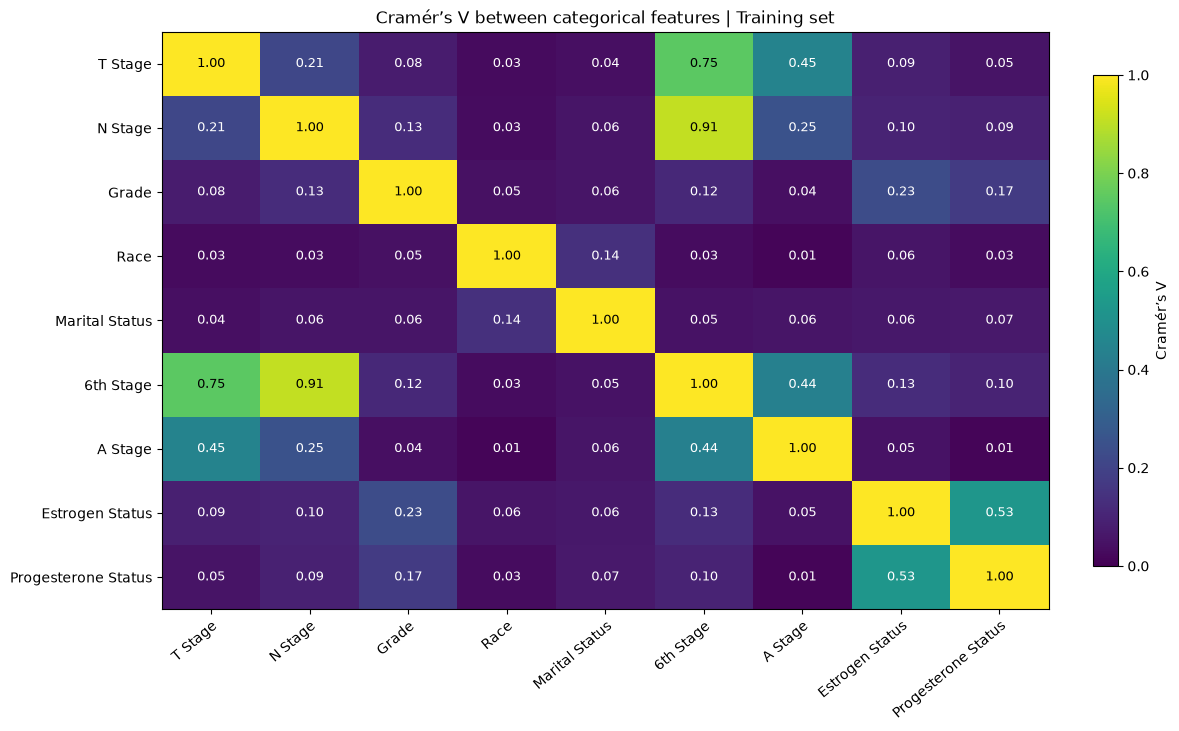

In [ ]:
cramers_matrix = pd.DataFrame(np.nan, index=CAT_FEATURES, columns=CAT_FEATURES, dtype=float)
for feature in CAT_FEATURES:
    if relationship_data[feature].nunique(dropna=True) > 1:
        cramers_matrix.loc[feature, feature] = 1.0
for first, second in combinations(CAT_FEATURES, 2):
    value = cramers_v(relationship_data[first], relationship_data[second])
    cramers_matrix.loc[first, second] = value
    cramers_matrix.loc[second, first] = value

display(cramers_matrix.round(3))
plot_relationship_matrix(cramers_matrix, "Cramér’s V between categorical features | Training set",
                         "Cramér’s V", cmap="viridis", vmin=0, vmax=1)


### 9.3 Clinical Stages: Detailed Cross-Tabulations

These are the stage comparisons previously placed before the EDA, now grouped with feature relationships. For each row category, the first table shows patient counts and the second shows percentages across 6th Stage categories. Each percentage uses its own row total as denominator. Small row counts make percentages less stable.


In [ ]:
for column in ["T Stage", "N Stage", "A Stage"]:
    counts = pd.crosstab(X_train[column], X_train["6th Stage"])
    row_percentages = counts.div(counts.sum(axis=1), axis=0) * 100
    print(f"\n{column} vs 6th Stage: number of patients")
    display(counts)
    print(f"{column} vs 6th Stage: percentages within each {column} category")
    display(row_percentages.round(1))



T Stage vs 6th Stage: number of patients


6th Stage,IIA,IIB,IIIA,IIIB,IIIC
T Stage,,,,,
T1,793,0,121,0,57
T2,0,661,253,0,154
T3,0,0,265,0,75
T4,0,0,0,46,27


T Stage vs 6th Stage: percentages within each T Stage category


6th Stage,IIA,IIB,IIIA,IIIB,IIIC
T Stage,,,,,
T1,81.7,0.0,12.5,0.0,5.9
T2,0.0,61.9,23.7,0.0,14.4
T3,0.0,0.0,77.9,0.0,22.1
T4,0.0,0.0,0.0,63.0,37.0



N Stage vs 6th Stage: number of patients


6th Stage,IIA,IIB,IIIA,IIIB,IIIC
N Stage,,,,,
N1,793,661,165,20,0
N2,0,0,474,26,0
N3,0,0,0,0,313


... (2 outputs left out)


A Stage vs 6th Stage: number of patients


6th Stage,IIA,IIB,IIIA,IIIB,IIIC
A Stage,,,,,
Distant,0,0,0,18,37
Regional,793,661,639,28,276


A Stage vs 6th Stage: percentages within each A Stage category


6th Stage,IIA,IIB,IIIA,IIIB,IIIC
A Stage,,,,,
Distant,0.0,0.0,0.0,32.7,67.3
Regional,33.1,27.6,26.7,1.2,11.5


### 9.4 Numerical–Categorical Pairs: Correlation Ratio η

For each numerical and categorical pair, η summarizes the variation in the numerical feature explained by differences between category means. A larger value indicates greater separation of group means relative to overall variation. η has no direction, does not establish causality and can be sensitive to small groups and extreme values.


,T Stage,N Stage,Grade,Race,Marital Status,6th Stage,A Stage,Estrogen Status,Progesterone Status
Age,0.113,0.047,0.129,0.081,0.262,0.088,0.008,0.064,0.009
Tumor Size,0.872,0.277,0.132,0.022,0.037,0.605,0.141,0.089,0.075
Regional Node Examined,0.127,0.337,0.087,0.014,0.029,0.341,0.045,0.042,0.019
Reginol Node Positive,0.256,0.871,0.149,0.032,0.077,0.857,0.193,0.094,0.081


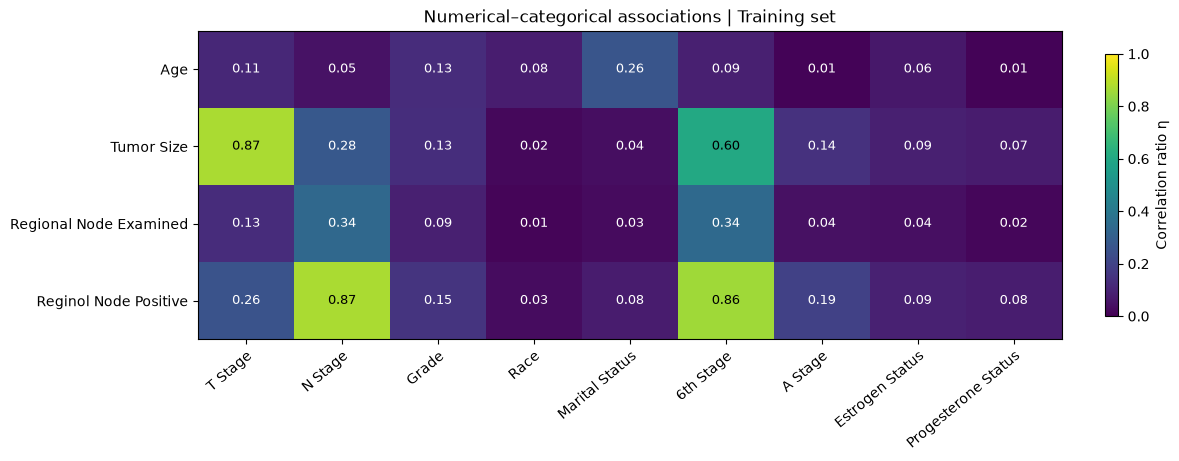

In [ ]:
eta_matrix = pd.DataFrame(index=NUM_FEATURES, columns=CAT_FEATURES, dtype=float)
for numerical in NUM_FEATURES:
    for categorical in CAT_FEATURES:
        eta_matrix.loc[numerical, categorical] = correlation_ratio(
            relationship_data[numerical], relationship_data[categorical]
        )
display(eta_matrix.round(3))
plot_relationship_matrix(eta_matrix, "Numerical–categorical associations | Training set",
                         "Correlation ratio η", cmap="viridis", vmin=0, vmax=1)


### 9.5 Example: Tumor Size by T Stage

This box plot complements the summary score with the actual distributions. The labels show group sizes; the central line and box represent the median and middle 50%. Points beyond the whiskers are not automatically erroneous observations.


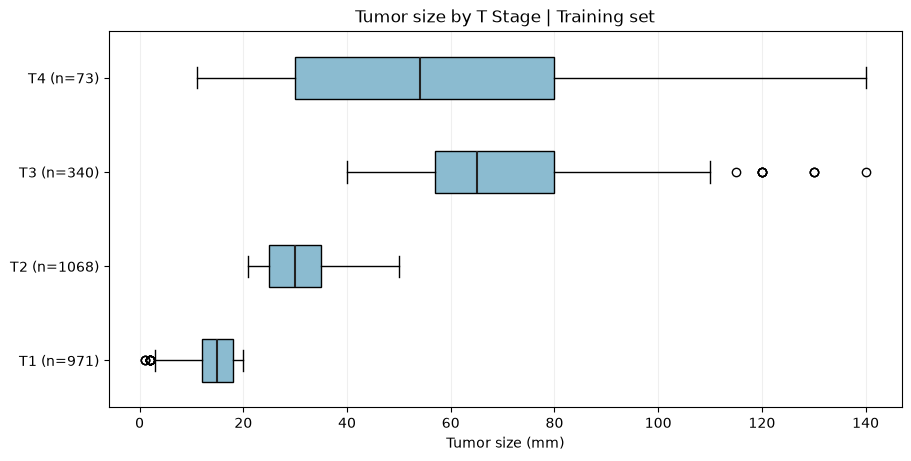

In [ ]:
from inspect import signature
stage_order = [stage for stage in ["T1", "T2", "T3", "T4"]
               if stage in relationship_data["T Stage"].dropna().unique()]
stage_groups = [relationship_data.loc[relationship_data["T Stage"] == stage, "Tumor Size"].dropna()
                for stage in stage_order]
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
orientation = {"orientation": "horizontal"} if "orientation" in signature(ax.boxplot).parameters else {"vert": False}
boxes = ax.boxplot(stage_groups, patch_artist=True, **orientation,
                   medianprops={"color": "#222222", "linewidth": 1.5})
for patch in boxes["boxes"]:
    patch.set_facecolor("#8bbbd0")
ax.set_yticks(range(1, len(stage_order) + 1),
              [f"{stage} (n={len(group)})" for stage, group in zip(stage_order, stage_groups)])
ax.set_xlabel("Tumor size (mm)")
ax.set_title("Tumor size by T Stage | Training set")
ax.grid(axis="x", alpha=0.2)
plt.show()


### 9.6 Complete Pairwise Results

The tables below list **all unique pairs** with the number of complete observations used. Numerical pairs retain the sign of Spearman correlation; the other two metrics are unsigned. Sorting highlights larger values within each method, but does not determine which variables should be kept or removed.


In [ ]:
pair_results = []
for first, second in combinations(NUM_FEATURES, 2):
    pair_results.append({"Type": "Numerical–numerical", "Feature 1": first, "Feature 2": second,
                         "Metric": "Spearman", "Value": spearman_matrix.loc[first, second],
                         "Patients": relationship_data[[first, second]].dropna().shape[0]})
for first, second in combinations(CAT_FEATURES, 2):
    pair_results.append({"Type": "Categorical–categorical", "Feature 1": first, "Feature 2": second,
                         "Metric": "Cramér’s V", "Value": cramers_matrix.loc[first, second],
                         "Patients": relationship_data[[first, second]].dropna().shape[0]})
for numerical in NUM_FEATURES:
    for categorical in CAT_FEATURES:
        pair_results.append({"Type": "Numerical–categorical", "Feature 1": numerical, "Feature 2": categorical,
                             "Metric": "Correlation ratio η", "Value": eta_matrix.loc[numerical, categorical],
                             "Patients": relationship_data[[numerical, categorical]].dropna().shape[0]})

pairwise_results = pd.DataFrame(pair_results)
assert len(pairwise_results) == len(list(combinations(relationship_data.columns, 2)))
for kind in ["Numerical–numerical", "Categorical–categorical", "Numerical–categorical"]:
    rows = pairwise_results[pairwise_results["Type"] == kind].copy()
    rows = rows.sort_values("Value", key=lambda values: values.abs(), ascending=False)
    print(f"{kind}: {len(rows)} unique pairs")
    display(rows.drop(columns="Type").reset_index(drop=True).round({"Value": 3}))


Numerical–numerical: 6 unique pairs


,Feature 1,Feature 2,Metric,Value,Patients
0,Regional Node Examined,Reginol Node Positive,Spearman,0.378,2452
1,Tumor Size,Reginol Node Positive,Spearman,0.339,2452
2,Tumor Size,Regional Node Examined,Spearman,0.133,2452
3,Age,Tumor Size,Spearman,-0.111,2452
4,Age,Regional Node Examined,Spearman,-0.032,2452
5,Age,Reginol Node Positive,Spearman,-0.001,2452


Categorical–categorical: 36 unique pairs


,Feature 1,Feature 2,Metric,Value,Patients
0,N Stage,6th Stage,Cramér’s V,0.909,2452
1,T Stage,6th Stage,Cramér’s V,0.747,2452
2,Estrogen Status,Progesterone Status,Cramér’s V,0.527,2452
3,T Stage,A Stage,Cramér’s V,0.446,2452
4,6th Stage,A Stage,Cramér’s V,0.435,2452
5,N Stage,A Stage,Cramér’s V,0.253,2452
6,Grade,Estrogen Status,Cramér’s V,0.232,2452
7,T Stage,N Stage,Cramér’s V,0.213,2452
8,Grade,Progesterone Status,Cramér’s V,0.174,2452
9,Race,Marital Status,Cramér’s V,0.140,2452


Numerical–categorical: 36 unique pairs


,Feature 1,Feature 2,Metric,Value,Patients
0,Tumor Size,T Stage,Correlation ratio η,0.872,2452
1,Reginol Node Positive,N Stage,Correlation ratio η,0.871,2452
2,Reginol Node Positive,6th Stage,Correlation ratio η,0.857,2452
3,Tumor Size,6th Stage,Correlation ratio η,0.605,2452
4,Regional Node Examined,6th Stage,Correlation ratio η,0.341,2452
5,Regional Node Examined,N Stage,Correlation ratio η,0.337,2452
6,Tumor Size,N Stage,Correlation ratio η,0.277,2452
7,Age,Marital Status,Correlation ratio η,0.262,2452
8,Reginol Node Positive,T Stage,Correlation ratio η,0.256,2452
9,Reginol Node Positive,A Stage,Correlation ratio η,0.193,2452


### 9.7 Interpretation

Use these results to formulate questions for feature engineering and model interpretation. High association can reflect shared clinical information, but does not by itself make a feature unnecessary. Low pairwise association does not rule out nonlinear or multivariable relationships. Revisit candidate feature choices during training-set model development, keeping the test set reserved for final evaluation.


## 10. Feature Engineering: Positive Node Ratio

The EDA suggested that the number of positive nodes and the number examined describe related but distinct information. We create the fraction of examined nodes that are positive:

**Positive Node Ratio = regional nodes positive / regional nodes examined**

For example, 4 positive nodes among 10 examined give a ratio of 0.4. Both original counts remain available in the raw data. For the initial model we retain the number examined and the ratio, while excluding the separate positive-node count; the ratio alone would not distinguish the same fraction calculated from different numbers of nodes. Creating the ratio is a hypothesis to evaluate later, not evidence that it improves prediction. Since the calculation is done independently for each patient and uses neither the outcome nor a learned population statistic, it can be applied safely to training rows.

The function checks for missing, zero or negative denominators and invalid positive counts. If any are present, it stops with an explanation rather than silently inventing a value. The held-out test set is not transformed in this section; apply the same function to it only when performing final evaluation.


In [ ]:
def add_positive_node_ratio(features):
    """Return a copy with the positive-node fraction, after checking both counts."""
    result = features.copy()
    examined = result["Regional Node Examined"]
    positive = result["Reginol Node Positive"]
    invalid = (examined.isna() | positive.isna() | (examined <= 0) |
               (positive < 0) | (positive > examined))
    if invalid.any():
        raise ValueError("Cannot calculate Positive Node Ratio: check examined and positive node counts.")
    result["Positive Node Ratio"] = positive / examined
    return result

# Keep the original training features available for EDA and create a separate modeling table.
X_train_fe = add_positive_node_ratio(X_train)
print("Original training shape:", X_train.shape)
print("Training shape with engineered feature:", X_train_fe.shape)
print("Positive Node Ratio summary:")
display(X_train_fe["Positive Node Ratio"].describe().round(3).to_frame())


Original training shape: (2452, 13)
Training shape with engineered feature: (2452, 14)
Positive Node Ratio summary:


,Positive Node Ratio
count,2452.000
mean,0.330
std,0.290
min,0.020
25%,0.103
50%,0.214
75%,0.500
max,1.000


### 10.1 Explore the New Feature

Compare the distribution and median in each outcome group using training data. Also examine the ratio’s Spearman correlations with its original component counts. These relationships are expected because the ratio is derived from the counts. Any observed difference is descriptive; model comparison is still needed to determine whether the ratio is useful.


,Patients,Median ratio
Class 0: survived ≥5 years,2115,0.200
Class 1: died <5 years,337,0.435


Spearman correlations with the original node counts:


,Regional Node Examined,Reginol Node Positive
Positive Node Ratio,-0.324,0.661


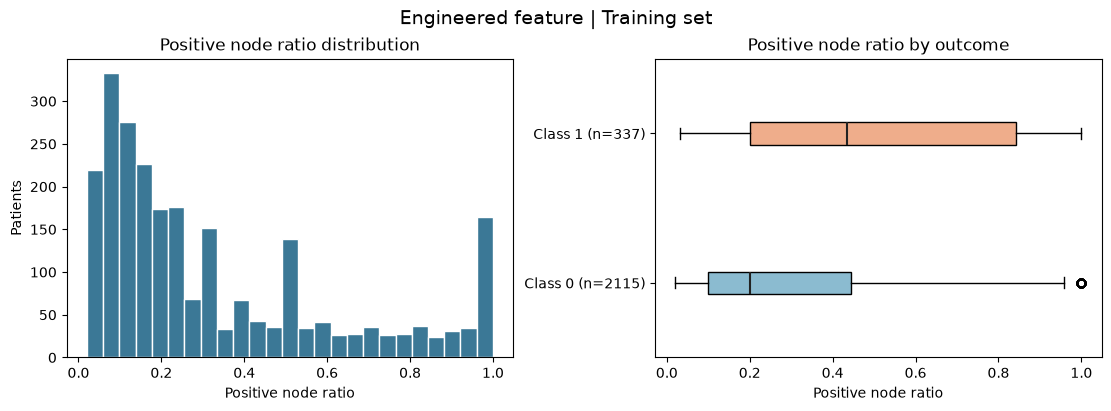

In [ ]:
ratio_eda = X_train_fe[["Positive Node Ratio"]].copy()
ratio_eda["label"] = y_train
ratio_by_outcome = ratio_eda.groupby("label")["Positive Node Ratio"].agg(["size", "median"])
ratio_by_outcome.index = ["Class 0: survived ≥5 years", "Class 1: died <5 years"]
display(ratio_by_outcome.rename(columns={"size": "Patients", "median": "Median ratio"}).round(3))

print("Spearman correlations with the original node counts:")
ratio_correlations = X_train_fe[["Positive Node Ratio", "Regional Node Examined", "Reginol Node Positive"]].corr(method="spearman")
display(ratio_correlations.loc[["Positive Node Ratio"], ["Regional Node Examined", "Reginol Node Positive"]].round(3))

from inspect import signature
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].hist(ratio_eda["Positive Node Ratio"], bins=25, color="#3b7896", edgecolor="white")
axes[0].set(title="Positive node ratio distribution", xlabel="Positive node ratio", ylabel="Patients")
groups = [ratio_eda.loc[ratio_eda["label"] == label, "Positive Node Ratio"] for label in (0, 1)]
orientation = {"orientation": "horizontal"} if "orientation" in signature(axes[1].boxplot).parameters else {"vert": False}
boxes = axes[1].boxplot(groups, patch_artist=True, **orientation,
                        medianprops={"color": "#222222", "linewidth": 1.5})
for patch, color in zip(boxes["boxes"], ["#8bbbd0", "#efad8b"]):
    patch.set_facecolor(color)
axes[1].set_yticks([1, 2], [f"Class 0 (n={len(groups[0])})", f"Class 1 (n={len(groups[1])})"])
axes[1].set(title="Positive node ratio by outcome", xlabel="Positive node ratio")
fig.suptitle("Engineered feature | Training set", fontsize=14)
plt.show()


### 10.2 Feature Selection: Overall Stage and Positive Node Count

The training-set EDA found a strong association between `6th Stage` and `N Stage` (Cramér’s V approximately 0.91), as well as between `6th Stage` and `T Stage` (approximately 0.75). The overall stage overlaps with information already represented in these features. As an initial choice, exclude `6th Stage` from the first model while keeping T and N stages separate and interpretable.

A strong association does not make these columns identical. Excluding `6th Stage` may discard information, so this decision should be revisited later by comparing models with and without it on training data. The original `X_train`, `X_test` and EDA retain `6th Stage`; only the modeling table excludes it.

We also exclude `Reginol Node Positive` from the first model after computing the ratio. Keeping `Regional Node Examined` and `Positive Node Ratio` preserves both the number examined and the fraction positive; their product reconstructs the positive count. However, a simple linear model cannot necessarily learn that multiplication automatically. This is an initial simplification to compare with the version that also includes the original count. The positive count remains in the original data and is required to calculate the ratio for new patients.


In [ ]:
# Keep the EDA data intact; remove two selected columns only after computing the ratio.
MODEL_EXCLUDED_COLS = ["6th Stage", "Reginol Node Positive"]
MODEL_CAT_COLS = [column for column in CAT_COLS if column not in MODEL_EXCLUDED_COLS]

def prepare_model_features(features):
    """Apply the same row-wise feature engineering and selection to new data."""
    engineered = add_positive_node_ratio(features)
    return engineered.drop(columns=MODEL_EXCLUDED_COLS)

X_train_model = prepare_model_features(X_train)
print("Original training features:", X_train.shape[1])
print("Model training features:", X_train_model.shape[1])
print("Excluded from model:", MODEL_EXCLUDED_COLS)
print("Engineered feature retained:", "Positive Node Ratio" in X_train_model.columns)


Original training features: 13
Model training features: 12
Excluded from model: ['6th Stage', 'Reginol Node Positive']
Engineered feature retained: True


## 11. Data Preprocessing: Feature-by-Feature Decisions

The EDA guides these initial choices. They are modeling decisions to evaluate later, rather than proof that a transformation improves prediction. Each numerical feature is standardized, while categorical features are encoded according to their meaning.

| Feature | Initial preprocessing | Why we chose it |
|---|---|---|
| `Age` | Standardize | Age is numerical and was not as strongly right-skewed as tumor size; scaling makes its magnitude comparable to other numerical inputs. |
| `Tumor Size` | `log1p`, then standardize | The training distribution has a long right tail. The logarithm compresses large values before scaling. |
| `Regional Node Examined` | Standardize | This is a numerical count. We retain its original scale relationship as the starting choice and scale it for scale-sensitive models. |
| `Reginol Node Positive` | Excluded from the first model | Used to calculate the ratio, then excluded to reduce overlapping information. Keep the raw column for EDA and for calculating the ratio on new patients. |
| `Positive Node Ratio` | Standardize | The engineered ratio is already bounded between 0 and 1; we do not apply the same logarithm automatically. Scaling keeps it comparable to the other numerical inputs. |
| `T Stage` | Ordinal encoding | The T categories have a clinical order, which we specify explicitly. |
| `N Stage` | Ordinal encoding | The N categories have a clinical order, which we specify explicitly. |
| `Grade` | Ordinal encoding | The histological grades have an ordered progression from I to IV. |
| `6th Stage` | Excluded from the first model | It overlaps strongly with T and N stages in the training EDA. Its exclusion is provisional and should be compared with inclusion during model development. |
| `A Stage` | One-hot encoding | Keep the recorded categories separate without imposing numerical distances. |
| `Race` | One-hot encoding | Keep the recorded categories separate; examine representation and fairness when interpreting model behavior. |
| `Marital Status` | One-hot encoding | These categories have no natural numerical order. |
| `Estrogen Status` | One-hot encoding | Keep receptor-status categories separate. |
| `Progesterone Status` | One-hot encoding | Keep receptor-status categories separate. |

`log1p(x)` means the natural logarithm of `1 + x`; it is defined at zero and reduces the spread of large nonnegative values. It does not guarantee a normal distribution or remove outliers. Negative or nonfinite tumor sizes are rejected so that data issues can be investigated.

Use `make_preprocessor()` inside each scikit-learn pipeline. The logarithm is a fixed row-wise transformation; scaler parameters and encoding must be fitted on training data only, separately within each training fold during model comparison. Keep the test set for final evaluation.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer

FEATURE_NUM_COLS = [column for column in NUM_COLS if column not in MODEL_EXCLUDED_COLS] + ["Positive Node Ratio"]
LOG_NUM_COLS = ["Tumor Size"]  # The training distribution has a long right tail.
SCALE_ONLY_COLS = ["Age", "Regional Node Examined", "Positive Node Ratio"]  # Start with scaling only.

# Check that each numerical feature has exactly one preprocessing route.
assert set(LOG_NUM_COLS).isdisjoint(SCALE_ONLY_COLS)
assert set(LOG_NUM_COLS) | set(SCALE_ONLY_COLS) == set(FEATURE_NUM_COLS)
assert set(FEATURE_NUM_COLS) | set(ORD_COLS) | set(MODEL_CAT_COLS) == set(X_train_model.columns)

# Explicit clinical order: OrdinalEncoder assigns 0 to the first level, 1 to the next, etc.
ORD_CATEGORIES = [
    ["T1", "T2", "T3", "T4"],  # Primary tumor stage.
    ["N1", "N2", "N3"],  # Regional lymph node stage.
    ["Well differentiated; Grade I", "Moderately differentiated; Grade II",
     "Poorly differentiated; Grade III", "Undifferentiated; anaplastic; Grade IV"],
]

def log1p_nonnegative(values):
    """Apply log(1 + x) only to finite, nonnegative tumor sizes."""
    numeric_values = np.asarray(values, dtype=float)
    if not np.isfinite(numeric_values).all() or (numeric_values < 0).any():
        raise ValueError("Tumor Size must be finite and nonnegative.")
    return np.log1p(values)

def make_preprocessor():
    # The logarithm is applied first; the scaler learns mean and deviation from training data.
    log_then_scale = Pipeline([
        ("log1p", FunctionTransformer(log1p_nonnegative, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("log_num", log_then_scale, LOG_NUM_COLS),
        ("scale_num", StandardScaler(), SCALE_ONLY_COLS),
        ("ord", OrdinalEncoder(categories=ORD_CATEGORIES), ORD_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), MODEL_CAT_COLS),  # Exclude 6th Stage from model inputs.
    ])


In [ ]:
# Sanity check only: fit a separate preprocessor on the engineered training data.
# During model comparison, create a fresh preprocessor inside each model pipeline.
preprocessor = make_preprocessor()
X_train_transformed = preprocessor.fit_transform(X_train_model)
print("X_train shape after preprocessing:", X_train_transformed.shape)
print("Example of generated feature names:", list(preprocessor.get_feature_names_out()[:7]), "...")


X_train shape after preprocessing: (2452, 21)
Example of generated feature names: ['log_num__Tumor Size', 'scale_num__Age', 'scale_num__Regional Node Examined', 'scale_num__Positive Node Ratio', 'ord__T Stage', 'ord__N Stage', 'ord__Grade'] ...


### 11.1 Visual Check: Distributions Before and After the Logarithm

Compare each selected training feature in its original form with `log1p`. The table also reports sample skewness before and after transformation. A smaller absolute skewness indicates a more symmetric distribution by this measure, but it does not by itself establish that the transformation improves the model. These plots show the values **before standardization** so the logarithm’s effect is visible.


,Original skewness,After log1p skewness
Tumor Size,1.665,-0.086


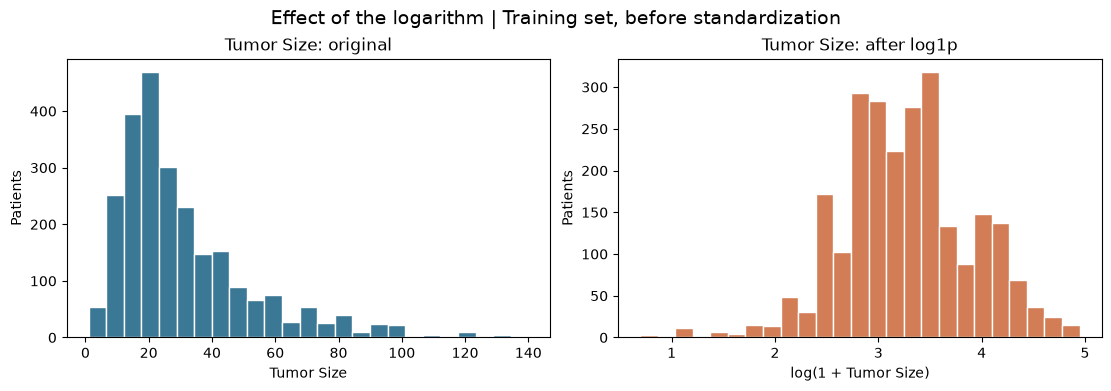

In [ ]:
log_skewness = pd.DataFrame({
    "Original skewness": X_train_model[LOG_NUM_COLS].skew(),
    "After log1p skewness": np.log1p(X_train_model[LOG_NUM_COLS]).skew(),
})
display(log_skewness.round(3))

fig, axes = plt.subplots(len(LOG_NUM_COLS), 2, figsize=(11, 3.8 * len(LOG_NUM_COLS)),
                         layout="constrained", squeeze=False)
for row, column in enumerate(LOG_NUM_COLS):
    values = X_train_model[column]
    axes[row, 0].hist(values, bins=25, color="#3b7896", edgecolor="white")
    axes[row, 0].set(title=f"{column}: original", xlabel=column, ylabel="Patients")
    axes[row, 1].hist(np.log1p(values), bins=25, color="#d27d55", edgecolor="white")
    axes[row, 1].set(title=f"{column}: after log1p", xlabel=f"log(1 + {column})", ylabel="Patients")
fig.suptitle("Effect of the logarithm | Training set, before standardization", fontsize=14)
plt.show()


**Modeling note:** Ordinal encoding preserves the order of T Stage, N Stage and Grade, but in a linear model a one-step increase is assumed to have the same effect across levels. This is a modeling assumption to consider when interpreting results. The other categorical features use one-hot encoding without dropping a reference level; consider a reference category if readily interpretable linear-model coefficients are needed.


## 12. Next Steps

Build model pipelines with fresh preprocessors and use `X_train_model` with `y_train` for development. When the final model has been selected, create the test feature table with `prepare_model_features(X_test)` and apply the fitted pipeline for final evaluation. For future patients, apply the same preparation function before using the model; alternatively, incorporate it into the model pipeline.
